<a href="https://colab.research.google.com/github/Niha5019/MLA0201-FOML/blob/main/EXP3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Decision Tree Classification
New Sample: {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'Normal', 'Wind': 'Weak'}
Prediction: Yes


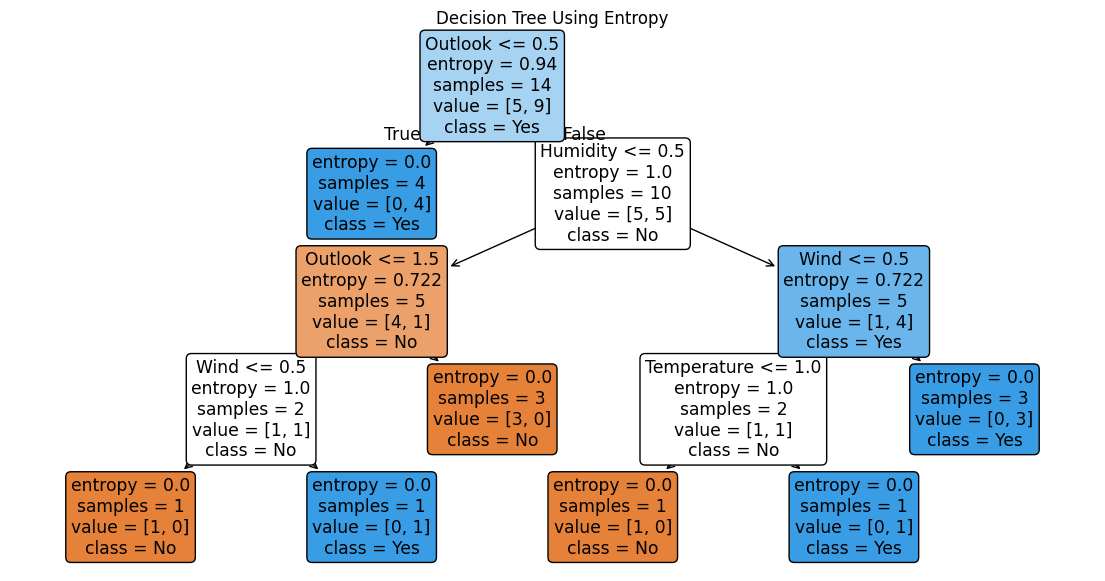

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder

# Training dataset
data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain',
                'Rain', 'Rain', 'Overcast', 'Sunny',
                'Sunny', 'Rain', 'Sunny', 'Overcast',
                'Overcast', 'Rain'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild',
                    'Cool', 'Cool', 'Cool', 'Mild',
                    'Cool', 'Mild', 'Mild', 'Mild',
                    'Hot', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High',
                 'Normal', 'Normal', 'Normal', 'High',
                 'Normal', 'Normal', 'Normal', 'High',
                 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak',
             'Weak', 'Strong', 'Strong', 'Weak',
             'Weak', 'Weak', 'Strong', 'Strong',
             'Weak', 'Strong'],
    'Play': ['No', 'No', 'Yes', 'Yes',
             'Yes', 'No', 'Yes', 'No',
             'Yes', 'Yes', 'Yes', 'Yes',
             'Yes', 'No']
}

df = pd.DataFrame(data)

# Encode categorical values
encoders = {}
X = df.drop('Play', axis=1).copy()

for col in X.columns:
    encoders[col] = LabelEncoder()
    X[col] = encoders[col].fit_transform(X[col])

y = LabelEncoder().fit_transform(df['Play'])

# Build decision tree using entropy (ID3 criterion)
model = DecisionTreeClassifier(criterion='entropy', random_state=0)
model.fit(X, y)

# Classify a new sample
sample = pd.DataFrame([{
    'Outlook': 'Sunny',
    'Temperature': 'Cool',
    'Humidity': 'Normal',
    'Wind': 'Weak'
}])

for col in sample.columns:
    sample[col] = encoders[col].transform(sample[col])

prediction = model.predict(sample)[0]
result = 'Yes' if prediction == 1 else 'No'

print("Decision Tree Classification")
print("New Sample:", {
    'Outlook': 'Sunny', 'Temperature': 'Cool',
    'Humidity': 'Normal', 'Wind': 'Weak'
})
print("Prediction:", result)

# Plot decision tree
plt.figure(figsize=(14, 7))
plot_tree(model, feature_names=X.columns,
          class_names=['No', 'Yes'],
          filled=True, rounded=True)
plt.title("Decision Tree Using Entropy")
plt.show()